In [1]:
!pip install shap lime scikit-learn pandas numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=40f285a22e520d2c6bc3c92c71a2fc1dbc12411281b1792b4bb5e75df787e029
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [4]:
from google.colab import files
uploaded = files.upload()

Saving german_credit.csv to german_credit.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

df = pd.read_csv('german_credit.csv')

print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (1000, 10)

Dataset Columns:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose']

First 5 Rows:


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car



Missing Values:
Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64


In [6]:
!pip install -q pandas numpy scikit-learn matplotlib shap lime

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split

# Download official UCI German Credit dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

df = pd.read_csv(url, sep=r"\s+", header=None)

print("Dataset downloaded")
print("Dataset shape:", df.shape)

Dataset downloaded
Dataset shape: (1000, 21)


In [8]:
columns = [
    "checking_status",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_status",
    "employment",
    "installment_rate",
    "personal_status",
    "other_parties",
    "residence_since",
    "property_magnitude",
    "age",
    "other_payment_plans",
    "housing",
    "existing_credits",
    "job",
    "num_dependents",
    "own_telephone",
    "foreign_worker",
    "class"
]

df.columns = columns

print("Column names assigned successfully!")
print("\nFirst 5 records:")
display(df.head())

Column names assigned successfully!

First 5 records:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [9]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nTarget Class Distribution:")
print(df["class"].value_counts())

print("\nDataset Description:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   checking_status      1000 non-null   object
 1   duration             1000 non-null   int64 
 2   credit_history       1000 non-null   object
 3   purpose              1000 non-null   object
 4   credit_amount        1000 non-null   int64 
 5   savings_status       1000 non-null   object
 6   employment           1000 non-null   object
 7   installment_rate     1000 non-null   int64 
 8   personal_status      1000 non-null   object
 9   other_parties        1000 non-null   object
 10  residence_since      1000 non-null   int64 
 11  property_magnitude   1000 non-null   object
 12  age                  1000 non-null   int64 
 13  other_payment_plans  1000 non-null   object
 14  housing              1000 non-null   object
 15  existing_credits     1000 non-null 

,duration,credit_amount,installment_rate,residence_since,age,existing_credits,num_dependents,class
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


In [10]:
df["class"] = df["class"].map({
    1: 0,
    2: 1
})

df.rename(columns={"class": "Risk"}, inplace=True)

print("Target encoding completed!")
print("\n0 = Good")
print("1 = Bad")

print("\nUpdated target distribution:")
print(df["Risk"].value_counts())

Target encoding completed!

0 = Good
1 = Bad

Updated target distribution:
Risk
0    700
1    300
Name: count, dtype: int64


In [11]:
X = df.drop("Risk", axis=1)

y = df["Risk"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (1000, 20)
Target Shape: (1000,)

Input Features:
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_rate', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']


In [12]:
categorical_columns = [
    "checking_status",
    "credit_history",
    "purpose",
    "savings_status",
    "employment",
    "personal_status",
    "other_parties",
    "property_magnitude",
    "other_payment_plans",
    "housing",
    "job",
    "own_telephone",
    "foreign_worker"
]

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

print("Categorical Columns:", len(categorical_columns))
print("Numerical Columns:", len(numerical_columns))

Categorical Columns: 13
Numerical Columns: 7


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data: (800, 20)
Testing Data: (200, 20)

Training Target Distribution:
Risk
0    560
1    240
Name: count, dtype: int64

Testing Target Distribution:
Risk
0    140
1     60
Name: count, dtype: int64


In [14]:
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train = X_train.copy()
X_test = X_test.copy()

# Fit and transform training data
X_train[categorical_columns] = encoder.fit_transform(
    X_train[categorical_columns]
)

# Transform testing data using the same encoder
X_test[categorical_columns] = encoder.transform(
    X_test[categorical_columns]
)

print("Ordinal Encoding Completed!")

print("\nEncoded Training Data:")
display(X_train.head())

print("\nEncoded Testing Data:")
display(X_test.head())

Ordinal Encoding Completed!

Encoded Training Data:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
828,0.0,36,2.0,1.0,8335,4.0,4.0,3,2.0,0.0,4,3.0,47,2.0,2.0,1,2.0,1,0.0,0.0
997,3.0,12,2.0,4.0,804,0.0,4.0,4,2.0,0.0,4,2.0,38,2.0,1.0,1,2.0,1,0.0,0.0
148,0.0,36,4.0,3.0,5371,0.0,2.0,3,2.0,2.0,2,1.0,28,2.0,1.0,2,2.0,1,0.0,0.0
735,1.0,36,1.0,5.0,3990,4.0,1.0,3,1.0,0.0,2,3.0,29,0.0,1.0,1,0.0,1,0.0,0.0
130,1.0,48,2.0,0.0,8487,4.0,3.0,1,1.0,0.0,2,2.0,24,2.0,1.0,1,2.0,1,0.0,0.0



Encoded Testing Data:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
30,1.0,18,2.0,9.0,1913,3.0,1.0,3,3.0,0.0,3,0.0,36,0.0,1.0,1,2.0,1,1.0,0.0
128,1.0,12,4.0,1.0,1860,0.0,0.0,4,2.0,0.0,2,2.0,34,2.0,1.0,2,3.0,1,1.0,0.0
289,0.0,24,3.0,4.0,1024,0.0,1.0,4,3.0,0.0,4,0.0,48,1.0,1.0,1,2.0,1,0.0,0.0
216,0.0,18,0.0,9.0,3104,0.0,3.0,3,2.0,0.0,1,1.0,31,0.0,1.0,1,2.0,1,1.0,0.0
966,1.0,27,4.0,4.0,2520,2.0,2.0,4,2.0,0.0,2,1.0,23,2.0,1.0,2,1.0,1,0.0,0.0


In [16]:
print("========== TASK 1 RESULTS ==========")

print("Total Records:", len(df))
print("Total Features:", X_train.shape[1])

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Categorical Features:", len(categorical_columns))
print("Numerical Features:", len(numerical_columns))

print("Missing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Testing:", X_test.isnull().sum().sum())

print("Random State: 42")
print("Test Size: 20%")
print("Stratified Split: Yes")


========== TASK 1 RESULTS ==========
Total Records: 1000
Total Features: 20
Training Samples: 800
Testing Samples: 200
Categorical Features: 13
Numerical Features: 7
Missing Values in Training: 0
Missing Values in Testing: 0
Random State: 42
Test Size: 20%
Stratified Split: Yes


In [ ]:
task 2

In [18]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [19]:
# Create Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


In [20]:
# Train the Random Forest Model

rf_model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [21]:
# Predict on testing data

y_pred = rf_model.predict(X_test)

# Predict probabilities of Bad class (1)

y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Predictions Completed Successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions Completed Successfully!

First 10 Actual Values:
[0 0 1 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 1 0 0 0 0 0 0 0]


In [22]:
# Calculate Accuracy

accuracy = accuracy_score(y_test, y_pred)

# Calculate ROC-AUC

roc_auc = roc_auc_score(y_test, y_pred_proba)

print("========== MODEL PERFORMANCE ==========")

print("Model: Random Forest")
print("Number of Trees: 200")
print("Maximum Depth: 8")

print("\nTest Accuracy:", round(accuracy, 4))
print("Test Accuracy (%):", round(accuracy * 100, 2), "%")

print("ROC-AUC Score:", round(roc_auc, 4))

========== MODEL PERFORMANCE ==========
Model: Random Forest
Number of Trees: 200
Maximum Depth: 8

Test Accuracy: 0.77
Test Accuracy (%): 77.0 %
ROC-AUC Score: 0.8113


Confusion Matrix:
[[130  10]
 [ 36  24]]


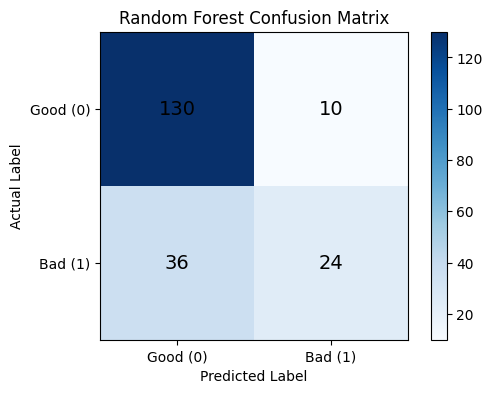

In [24]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

plt.imshow(cm, cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Good (0)", "Bad (1)"])
plt.yticks([0, 1], ["Good (0)", "Bad (1)"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center", fontsize=14)

plt.colorbar()
plt.show()

In [25]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Good", "Bad"]
    )
)

Classification Report:
              precision    recall  f1-score   support

        Good       0.78      0.93      0.85       140
         Bad       0.71      0.40      0.51        60

    accuracy                           0.77       200
   macro avg       0.74      0.66      0.68       200
weighted avg       0.76      0.77      0.75       200



In [27]:
 print("ROC-AUC Score:", round(roc_auc, 4))

ROC-AUC Score: 0.8113


In [ ]:
T3

In [28]:
import shap

print("SHAP Version:", shap.__version__)
print("SHAP imported successfully!")

SHAP Version: 0.54.1
SHAP imported successfully!


In [29]:
# Create SHAP TreeExplainer

explainer = shap.TreeExplainer(rf_model)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [30]:
# Calculate SHAP values for test data

shap_values = explainer.shap_values(X_test)

# Extract SHAP values for Bad class (class 1)

if isinstance(shap_values, list):
    shap_values_bad = shap_values[1]

elif len(shap_values.shape) == 3:
    shap_values_bad = shap_values[:, :, 1]

else:
    shap_values_bad = shap_values

print("SHAP Values Calculated Successfully!")

print("SHAP Shape:", shap_values_bad.shape)

SHAP Values Calculated Successfully!
SHAP Shape: (200, 20)


In [31]:
# Calculate mean absolute SHAP values

mean_shap = np.abs(shap_values_bad).mean(axis=0)

# Create feature importance DataFrame

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP": mean_shap
})

# Sort from highest to lowest

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP",
    ascending=False
)

print("GLOBAL SHAP FEATURE IMPORTANCE")

display(shap_importance.head(10))

print("\nTOP 5 FEATURES")

display(shap_importance.head(5))

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_SHAP
0,checking_status,0.086658
1,duration,0.041341
5,savings_status,0.039125
4,credit_amount,0.025849
2,credit_history,0.025785
6,employment,0.023986
13,other_payment_plans,0.022223
11,property_magnitude,0.019792
12,age,0.016870
7,installment_rate,0.016605



TOP 5 FEATURES


,Feature,Mean_SHAP
0,checking_status,0.086658
1,duration,0.041341
5,savings_status,0.039125
4,credit_amount,0.025849
2,credit_history,0.025785


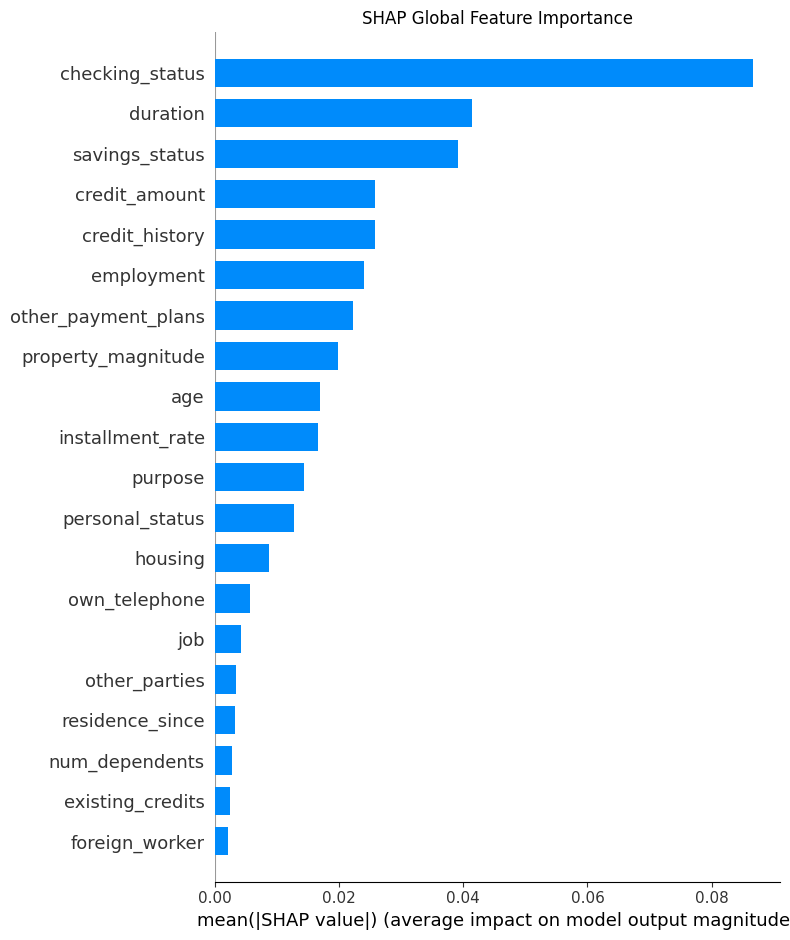

SHAP Summary Plot Saved Successfully!


In [32]:
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values_bad,
    X_test,
    plot_type="bar",
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()

plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")

plt.show()

print("SHAP Summary Plot Saved Successfully!")

In [33]:
top5_features = shap_importance.head(5)

top5_features.to_csv(
    "top5_shap_features.csv",
    index=False
)

print("Top 5 SHAP features saved successfully!")

Top 5 SHAP features saved successfully!


In [ ]:
T4

In [34]:
# Find applicants predicted as Bad (1)

rejected_indices = np.where(y_pred == 1)[0]

print("Total Rejected Applicants:", len(rejected_indices))

print("\nRejected Applicant Test Indices:")
print(rejected_indices)

Total Rejected Applicants: 34

Rejected Applicant Test Indices:
[  2  23  33  35  36  37  39  46  47  54  59  61  63  69  78  80  90  96
 129 132 135 140 141 156 160 162 167 175 178 181 183 185 191 195]


In [35]:
# Select first rejected applicant

applicant_idx = rejected_indices[0]

print("Selected Applicant Index:", applicant_idx)

print("Actual Risk:", y_test.iloc[applicant_idx])

print("Predicted Risk:", y_pred[applicant_idx])

print("Probability of Bad:", round(y_pred_proba[applicant_idx], 4))

Selected Applicant Index: 2
Actual Risk: 1
Predicted Risk: 1
Probability of Bad: 0.5328


In [36]:
# Get SHAP values for selected applicant

applicant_shap = shap_values_bad[applicant_idx]

# Get applicant data

applicant_data = X_test.iloc[applicant_idx]

print("Applicant Data:")
display(applicant_data.to_frame("Value"))

print("\nApplicant SHAP Values:")
display(pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP Value": applicant_shap
}).sort_values("SHAP Value", ascending=False))

Applicant Data:


,Value
checking_status,0.0
duration,24.0
credit_history,3.0
purpose,4.0
credit_amount,1024.0
savings_status,0.0
employment,1.0
installment_rate,4.0
personal_status,3.0
other_parties,0.0



Applicant SHAP Values:


,Feature,SHAP Value
0,checking_status,0.113414
1,duration,0.048635
6,employment,0.036817
5,savings_status,0.035677
13,other_payment_plans,0.028934
7,installment_rate,0.026791
4,credit_amount,0.011455
18,own_telephone,0.002904
19,foreign_worker,0.002814
9,other_parties,0.002426


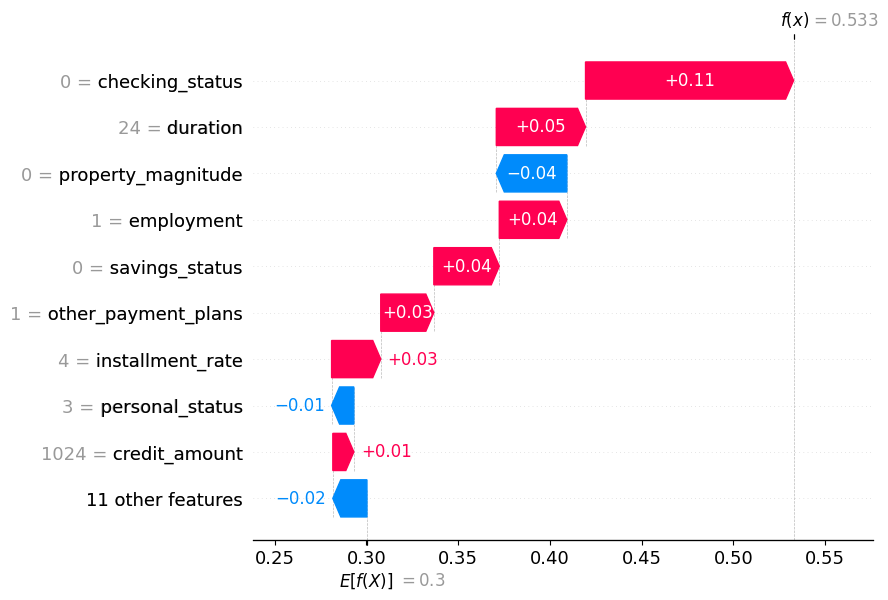

<Figure size 640x480 with 0 Axes>

In [37]:
# Create explanation for selected applicant

base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = base_value[1]

explanation = shap.Explanation(
    values=applicant_shap,
    base_values=base_value,
    data=applicant_data.values,
    feature_names=X_test.columns.tolist()
)

# Draw waterfall plot

shap.plots.waterfall(
    explanation,
    max_display=10
)

plt.savefig("shap_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

In [38]:
# Sort SHAP contributions by absolute magnitude

local_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Value": applicant_data.values,
    "SHAP Value": applicant_shap
})

local_importance["Absolute SHAP"] = abs(
    local_importance["SHAP Value"]
)

local_importance = local_importance.sort_values(
    "Absolute SHAP",
    ascending=False
)

print("TOP 3 SHAP REASONS")

display(local_importance.head(3))

TOP 3 SHAP REASONS


,Feature,Value,SHAP Value,Absolute SHAP
0,checking_status,0.0,0.113414,0.113414
1,duration,24.0,0.048635,0.048635
11,property_magnitude,0.0,-0.038444,0.038444


In [ ]:
T5

In [39]:
from lime.lime_tabular import LimeTabularExplainer

print("LIME imported successfully!")

LIME imported successfully!


In [40]:
# Get categorical feature positions

categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_columns
]

# Create category names for LIME

categorical_names = {}

for i, col in enumerate(categorical_columns):
    feature_index = X_train.columns.get_loc(col)

    categorical_names[feature_index] = [
        str(category)
        for category in encoder.categories_[i]
    ]

# Create LIME explainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["Good", "Bad"],
    categorical_features=categorical_indices,
    categorical_names=categorical_names,
    mode="classification",
    random_state=42
)

print("LIME Explainer Created Successfully!")

LIME Explainer Created Successfully!


In [41]:
# Select the same applicant used in SHAP

applicant = X_test.iloc[applicant_idx].values

# Generate LIME explanation

lime_exp = lime_explainer.explain_instance(
    data_row=applicant,
    predict_fn=rf_model.predict_proba,
    num_features=5,
    labels=(1,)
)

print("LIME Explanation Generated Successfully!")

print("\nLIME TOP 5 REASONS:")

for feature, contribution in lime_exp.as_list(label=1):
    print(feature, ":", round(contribution, 5))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


LIME Explanation Generated Successfully!

LIME TOP 5 REASONS:
checking_status=A11 : 0.13535
savings_status=A61 : 0.06177
employment=A72 : 0.05718
3.00 < installment_rate <= 4.00 : 0.0375
property_magnitude=A121 : -0.03297


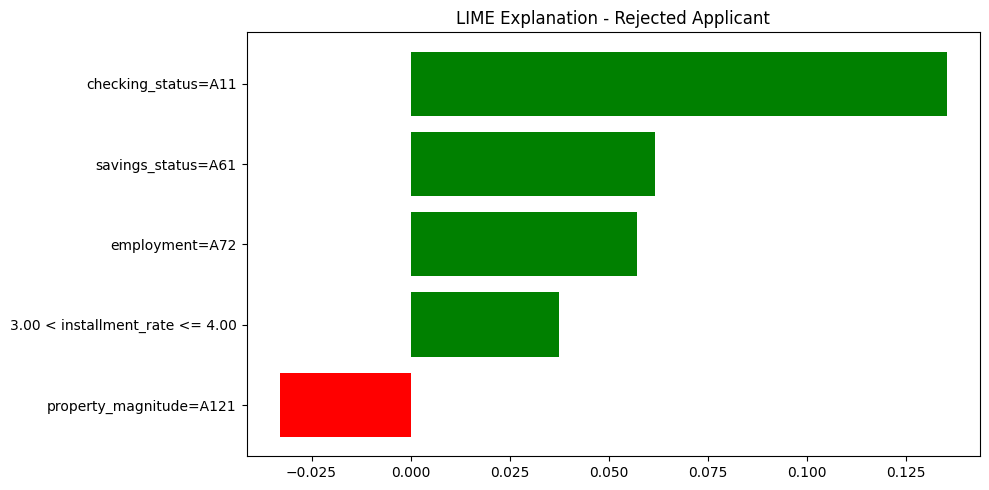

LIME Plot Saved Successfully!


In [42]:
fig = lime_exp.as_pyplot_figure(label=1)

fig.set_size_inches(10, 5)

plt.title("LIME Explanation - Rejected Applicant")

plt.tight_layout()

plt.savefig(
    "lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("LIME Plot Saved Successfully!")

In [43]:
# Top 3 SHAP features by absolute contribution

shap_top3 = (
    local_importance
    .head(3)["Feature"]
    .tolist()
)

# Top 3 LIME features by absolute contribution

lime_results = lime_exp.as_list(label=1)

lime_top3 = [
    feature.split(" ")[0].split("=")[0]
    for feature, contribution in lime_results[:3]
]

# Calculate agreement

agreement = len(set(shap_top3) & set(lime_top3))

print("SHAP Top 3:", shap_top3)

print("\nLIME Top 3:", lime_top3)

print("\nTop 3 Agreement:", agreement, "/ 3")

SHAP Top 3: ['checking_status', 'duration', 'property_magnitude']

LIME Top 3: ['checking_status', 'savings_status', 'employment']

Top 3 Agreement: 1 / 3


In [ ]:
T6

In [44]:
# Sensitive attributes mentioned in the question paper

sensitive_attributes = [
    "age",
    "personal_status",
    "foreign_worker"
]

# Collect top 3 SHAP features
shap_features = local_importance.head(3)["Feature"].tolist()

# Collect top 5 LIME features
lime_features = [
    feature
    for feature, contribution in lime_results
]

# Check whether sensitive attributes appear
all_reasons = shap_features + lime_features

sensitive_found = [
    attribute
    for attribute in sensitive_attributes
    if any(attribute in reason for reason in all_reasons)
]

print("SHAP Reasons:", shap_features)

print("\nLIME Reasons:")
for feature, contribution in lime_results:
    print(feature)

print("\nSensitive Attributes Found:", sensitive_found)

if len(sensitive_found) == 0:
    print("\nRESULT: No sensitive attributes found among the reasons.")
else:
    print("\nRESULT: Sensitive attributes detected. REVIEW REQUIRED.")

SHAP Reasons: ['checking_status', 'duration', 'property_magnitude']

LIME Reasons:
checking_status=A11
savings_status=A61
employment=A72
3.00 < installment_rate <= 4.00
property_magnitude=A121

Sensitive Attributes Found: []

RESULT: No sensitive attributes found among the reasons.


In [45]:
print("Final Accuracy:", round(accuracy, 4))
print("Final ROC-AUC:", round(roc_auc, 4))

Final Accuracy: 0.77
Final ROC-AUC: 0.8113
